# Transcriptomic Analysis of Oxidative Stress Pathways in Symptomatic vs. Asymptomatic Carotid Atherosclerotic Plaque
Dataset: GSE21545 — Biobank of Karolinska Endarterectomy (BiKE), Affymetrix GPL570, 223 samples (paired plaque + PBMC, ~111 patients), with age/ischemic-event annotation.
Author: Abdulmuhsen Almutairi — MSc Biochemistry, University of Jeddah
Research question: Which oxidative stress / antioxidant defense genes are significantly dysregulated in symptomatic vs. asymptomatic carotid plaque, adjusting for patient age?

In [1]:
import os, gzip, urllib.request, shutil
from io import StringIO

import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk")
pd.set_option("display.max_columns", 20)

GROUP_COLORS = {"Symptomatic": "#C44E52", "Asymptomatic": "#55A868"}

In [2]:
SERIES_MATRIX_URL = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE21nnn/GSE21545/matrix/GSE21545_series_matrix.txt.gz"
PLATFORM_SOFT_URL = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE21nnn/GSE21545/soft/GSE21545_family.soft.gz"

DATA_DIR, RESULTS_DIR, FIGURES_DIR = "data", "results", "figures"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

ALPHA_FDR = 0.05
LOG2FC_THRESHOLD = 0.585

OXIDATIVE_STRESS_PANEL = {
    "Superoxide dismutases": ["SOD1", "SOD2", "SOD3"],
    "Catalase / peroxide detox": ["CAT", "GPX1", "GPX2", "GPX3", "GPX4", "GPX7"],
    "Glutathione synthesis & redox cycling": ["GCLC", "GCLM", "GSS", "GSR", "GSTP1", "GSTM1", "GSTM3"],
    "Thioredoxin / peroxiredoxin system": ["TXN", "TXN2", "TXNRD1", "TXNRD2", "PRDX1", "PRDX2", "PRDX3", "PRDX4", "PRDX5", "PRDX6"],
    "Nrf2-Keap1 antioxidant response": ["NFE2L2", "KEAP1", "HMOX1", "NQO1"],
    "ROS-generating enzymes": ["NOX1", "NOX4", "NOS3", "XDH", "MPO"],
    "Metal-binding / auxiliary": ["MT1A", "MT2A", "CP", "SELENOP"],
}
ALL_PANEL_GENES = sorted({g for genes in OXIDATIVE_STRESS_PANEL.values() for g in genes})

In [3]:
def _download(url, dest_path):
    if os.path.exists(dest_path):
        print(f"[skip] {dest_path} already exists")
        return dest_path
    print(f"[download] {url}")
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=120) as response, open(dest_path, "wb") as out:
        shutil.copyfileobj(response, out)
    print(f"[ok] saved to {dest_path}")
    return dest_path

series_matrix_path = _download(SERIES_MATRIX_URL, os.path.join(DATA_DIR, "GSE21545_series_matrix.txt.gz"))
platform_soft_path = _download(PLATFORM_SOFT_URL, os.path.join(DATA_DIR, "GSE21545_family.soft.gz"))

[skip] data\GSE21545_series_matrix.txt.gz already exists
[skip] data\GSE21545_family.soft.gz already exists


In [4]:
def _open_maybe_gz(path):
    return gzip.open(path, "rt", encoding="latin-1", errors="replace")

meta, table_lines, in_table = {}, [], False
with _open_maybe_gz(series_matrix_path) as fh:
    for line in fh:
        line = line.rstrip("\n")
        if line.startswith("!series_matrix_table_begin"):
            in_table = True; continue
        if line.startswith("!series_matrix_table_end"):
            in_table = False; continue
        if in_table:
            table_lines.append(line); continue
        if line.startswith("!Sample_"):
            parts = line.split("\t")
            key = parts[0].lstrip("!")
            vals = [v.strip('"') for v in parts[1:]]
            meta.setdefault(key, []).append(vals)

expr_df = pd.read_csv(StringIO("\n".join(table_lines)), sep="\t", index_col=0)
expr_df.columns = [c.strip('"') for c in expr_df.columns]

accessions = meta["Sample_geo_accession"][0]
titles = meta["Sample_title"][0]
sample_meta = pd.DataFrame({"geo_accession": accessions, "title": titles}).set_index("geo_accession").loc[expr_df.columns]

for row in meta.get("Sample_characteristics_ch1", []):
    if not row or ":" not in row[0]:
        continue
    key_name = row[0].split(":")[0].strip()
    values = [v.split(":", 1)[1].strip() if ":" in v else v for v in row]
    sample_meta[key_name] = values

sample_meta["age"] = pd.to_numeric(sample_meta.get("age (y)"), errors="coerce")
sample_meta["is_plaque"] = sample_meta.get("sample type", "").str.lower().str.contains("plaque")
sample_meta["ischemic_event"] = sample_meta.get("ischemic event", "").str.upper() == "TRUE"
sample_meta["group"] = np.where(sample_meta["ischemic_event"], "Symptomatic", "Asymptomatic")

plaque_meta = sample_meta[sample_meta["is_plaque"]].copy()
print(f"Total samples: {expr_df.shape[1]}, Plaque samples: {len(plaque_meta)}")
plaque_meta["group"].value_counts()

Total samples: 223, Plaque samples: 126


group
Asymptomatic    101
Symptomatic      25
Name: count, dtype: int64

In [5]:
table_lines2, in_table2 = [], False
with _open_maybe_gz(platform_soft_path) as fh:
    for line in fh:
        line = line.rstrip("\n")
        if line.startswith("!platform_table_begin"):
            in_table2 = True; continue
        if line.startswith("!platform_table_end"):
            in_table2 = False; continue
        if in_table2:
            table_lines2.append(line)

plat_df = pd.read_csv(StringIO("\n".join(table_lines2)), sep="\t", low_memory=False)
gene_col = next((c for c in ["Gene Symbol", "GENE_SYMBOL", "Symbol", "GeneSymbol"] if c in plat_df.columns), None)
probe2gene = dict(zip(plat_df["ID"].astype(str), plat_df[gene_col].astype(str)))

gene_series = expr_df.index.to_series().map(probe2gene)
valid = gene_series.notna() & (gene_series != "") & (gene_series != "nan")
mapped = expr_df.loc[valid].copy()
mapped["gene_symbol"] = gene_series[valid]
gene_df = mapped.groupby("gene_symbol").mean(numeric_only=True)

gene_df_plaque = gene_df[plaque_meta.index]
print(f"Genes (collapsed): {gene_df.shape[0]}")

Genes (collapsed): 23520


              count   mean       std   min   25%   50%   75%   max
group                                                             
Asymptomatic  100.0  69.76  8.651642  48.0  63.0  70.0  77.0  84.0
Symptomatic    25.0  74.04  9.176419  46.0  71.0  76.0  81.0  85.0


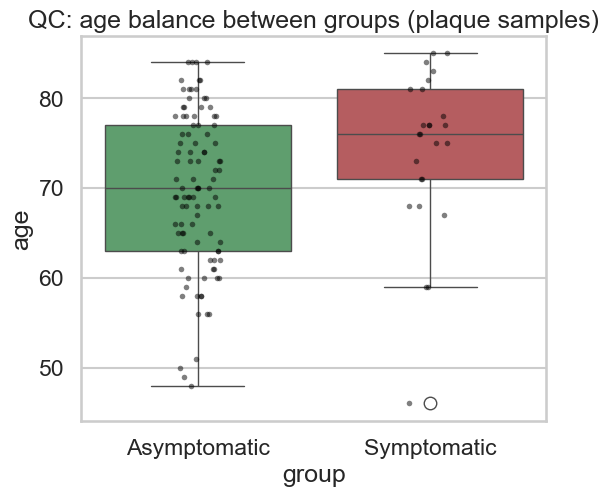

In [6]:
print(plaque_meta.groupby("group")["age"].describe())

fig, ax = plt.subplots(figsize=(6, 5))
sns.boxplot(data=plaque_meta, x="group", y="age", ax=ax, hue="group", palette=GROUP_COLORS, legend=False)
sns.stripplot(data=plaque_meta, x="group", y="age", ax=ax, color="black", size=4, alpha=0.5)
ax.set_title("QC: age balance between groups (plaque samples)")
plt.savefig(os.path.join(FIGURES_DIR, "age_balance_check.png"), dpi=300)
plt.show()

In [7]:
def run_simple_ttest(gene_df, sample_meta):
    sym = sample_meta.index[sample_meta["group"] == "Symptomatic"]
    asym = sample_meta.index[sample_meta["group"] == "Asymptomatic"]
    results = []
    for gene in gene_df.index:
        a = gene_df.loc[gene, sym].dropna().values
        c = gene_df.loc[gene, asym].dropna().values
        if len(a) < 3 or len(c) < 3:
            continue
        t_stat, p_val = stats.ttest_ind(a, c, equal_var=False)
        results.append({"gene_symbol": gene, "log2FC": np.mean(a) - np.mean(c),
                         "t_stat": t_stat, "p_value": p_val, "n_symptomatic": len(a), "n_asymptomatic": len(c)})
    de = pd.DataFrame(results).dropna(subset=["p_value"])
    de["fdr"] = multipletests(de["p_value"], method="fdr_bh")[1]
    de["significant"] = (de["fdr"] < ALPHA_FDR) & (de["log2FC"].abs() >= LOG2FC_THRESHOLD)
    return de.sort_values("fdr").reset_index(drop=True)

simple_de = run_simple_ttest(gene_df_plaque, plaque_meta)
print(f"Simple t-test — significant: {simple_de['significant'].sum()} / {len(simple_de)}")
simple_de.head(10)

Simple t-test — significant: 0 / 23520


,gene_symbol,log2FC,t_stat,p_value,n_symptomatic,n_asymptomatic,fdr,significant
0,LOC101928907,0.065042,1.133996,0.263947,25,101,0.979177,False
1,LOC102725438,0.053800,0.786649,0.437325,25,101,0.979177,False
2,LOC102725451 /// TPTEP1,0.056456,0.611657,0.544134,25,101,0.979177,False
3,LOC103344931,-0.058659,-0.984707,0.330236,25,101,0.979177,False
4,LOC113230 /// MIR1199,0.096893,0.938147,0.354157,25,101,0.979177,False
5,LOC142937,0.090105,1.121410,0.270416,25,101,0.979177,False
6,LOC143188 /// VTI1A,0.222090,1.772103,0.084784,25,101,0.979177,False
7,TDRG1,0.150006,1.204155,0.237151,25,101,0.979177,False
8,LOC145678,0.090506,1.208803,0.234733,25,101,0.979177,False
9,LOC145694,0.091780,0.960784,0.342870,25,101,0.979177,False


In [8]:

from scipy import stats as scipy_stats

def run_age_adjusted_model_fast(gene_df, sample_meta):
    df_model = sample_meta[["group", "age"]].copy().dropna()
    samples = df_model.index

    n = len(samples)
    group_dummy = (df_model["group"] == "Symptomatic").astype(float).values
    age = df_model["age"].values.astype(float)
    X = np.column_stack([np.ones(n), group_dummy, age])  # [intercept, group, age]

    Y = gene_df[samples].values.T  # samples x genes

    XtX_inv = np.linalg.pinv(X.T @ X)
    beta = XtX_inv @ X.T @ Y  # (3, n_genes) -- all coefficients, all genes, one shot

    residuals = Y - X @ beta
    dof = n - X.shape[1]
    rss = np.sum(residuals**2, axis=0)
    sigma2 = rss / dof

    se_group = np.sqrt(sigma2 * XtX_inv[1, 1])
    t_stat = beta[1] / se_group
    p_value = 2 * scipy_stats.t.sf(np.abs(t_stat), dof)

    de = pd.DataFrame({
        "gene_symbol": gene_df.index,
        "log2FC_adj": beta[1],
        "p_value_adj": p_value,
    }).dropna(subset=["p_value_adj"])
    de["fdr_adj"] = multipletests(de["p_value_adj"], method="fdr_bh")[1]
    de["significant_adj"] = (de["fdr_adj"] < ALPHA_FDR) & (de["log2FC_adj"].abs() >= LOG2FC_THRESHOLD)
    return de.sort_values("fdr_adj").reset_index(drop=True)

adjusted_de = run_age_adjusted_model_fast(gene_df_plaque, plaque_meta)
print(f"Age-adjusted model — significant: {adjusted_de['significant_adj'].sum()} / {len(adjusted_de)}")

Age-adjusted model — significant: 0 / 23520


In [9]:
fdr_only = (adjusted_de["fdr_adj"] < ALPHA_FDR).sum()
fc_only = (adjusted_de["log2FC_adj"].abs() >= LOG2FC_THRESHOLD).sum()
print(f"Genes passing FDR<0.05 alone (any fold-change): {fdr_only}")
print(f"Genes passing |log2FC|>=0.585 alone (any FDR): {fc_only}")

print("\nTop 10 genes by FDR (regardless of threshold):")
print(adjusted_de[["gene_symbol","log2FC_adj","p_value_adj","fdr_adj"]].head(10))

panel_check = adjusted_de[adjusted_de["gene_symbol"].isin(ALL_PANEL_GENES)].sort_values("p_value_adj")
print("\nOxidative stress panel genes, ranked by raw p-value (nominal, exploratory):")
print(panel_check[["gene_symbol","log2FC_adj","p_value_adj","fdr_adj"]])

Genes passing FDR<0.05 alone (any fold-change): 0
Genes passing |log2FC|>=0.585 alone (any FDR): 3

Top 10 genes by FDR (regardless of threshold):
    gene_symbol  log2FC_adj  p_value_adj   fdr_adj
0  LOC101928907    0.083586     0.159398  0.913022
1        TMIGD2    0.099829     0.193951  0.913022
2  LOC101929473    0.046138     0.241198  0.913022
3  LOC101929478    0.060952     0.335472  0.913022
4  LOC101929480    0.054416     0.287987  0.913022
5  LOC101929486    0.050501     0.342935  0.913022
6  LOC101929488    0.099472     0.181284  0.913022
7  LOC101929497    0.087615     0.246104  0.913022
8  LOC101929505   -0.037874     0.465232  0.913022
9  LOC101929511    0.049696     0.148113  0.913022

Oxidative stress panel genes, ranked by raw p-value (nominal, exploratory):
      gene_symbol  log2FC_adj  p_value_adj   fdr_adj
13206        GPX2    0.160788     0.058100  0.913022
1285          MPO    0.072582     0.135576  0.913022
6950         NOX4   -0.288031     0.172986  0.913022
121

In [10]:
from scipy.stats import mannwhitneyu

adjusted_de["signed_score"] = -np.log10(adjusted_de["p_value_adj"]) * np.sign(adjusted_de["log2FC_adj"])

is_panel = adjusted_de["gene_symbol"].isin(ALL_PANEL_GENES)
panel_scores = adjusted_de.loc[is_panel, "signed_score"].abs()
background_scores = adjusted_de.loc[~is_panel, "signed_score"].abs()

u_stat, p_value = mannwhitneyu(panel_scores, background_scores, alternative="greater")

print(f"Rank-based (GSEA-style) enrichment test:")
print(f"Median |signed score| -- panel: {panel_scores.median():.3f}, background: {background_scores.median():.3f}")
print(f"Mann-Whitney U p-value: {p_value:.4g}")

Rank-based (GSEA-style) enrichment test:
Median |signed score| -- panel: 0.231, background: 0.339
Mann-Whitney U p-value: 0.9641


## 10. Positive control: tissue-of-origin signal (Plaque vs. PBMC)

Repeats the identical statistical pipeline on a stronger, biologically well-established
contrast within the same cohort (Plaque vs. matched PBMC, same patients) to confirm the
pipeline detects real signal when present.

In [13]:
import numpy as np

sample_meta["tissue"] = np.where(sample_meta["is_plaque"], "Plaque", "PBMC")

pair_counts = sample_meta.groupby("individual")["tissue"].nunique()
paired_ids = pair_counts[pair_counts == 2].index
paired_meta = sample_meta[sample_meta["individual"].isin(paired_ids)].copy()

plaque_ids = paired_meta[paired_meta["tissue"] == "Plaque"].sort_values("individual").index
pbmc_ids = paired_meta[paired_meta["tissue"] == "PBMC"].sort_values("individual").index
assert (paired_meta.loc[plaque_ids, "individual"].values == paired_meta.loc[pbmc_ids, "individual"].values).all()

print(f"Total samples: {len(sample_meta)}")
print(f"Matched patients (Plaque + PBMC pair): {len(plaque_ids)}")

Total samples: 223
Matched patients (Plaque + PBMC pair): 96


In [14]:
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

plaque_vals = gene_df[plaque_ids].values
pbmc_vals = gene_df[pbmc_ids].values

log2fc = plaque_vals.mean(axis=1) - pbmc_vals.mean(axis=1)
t_stat, p_value = ttest_rel(plaque_vals, pbmc_vals, axis=1)

tissue_de = pd.DataFrame({
    "gene_symbol": gene_df.index,
    "log2FC_plaque_vs_pbmc": log2fc,
    "p_value": p_value,
}).dropna(subset=["p_value"])

tissue_de["fdr"] = multipletests(tissue_de["p_value"], method="fdr_bh")[1]
tissue_de["significant"] = (
    (tissue_de["fdr"] < ALPHA_FDR) & (tissue_de["log2FC_plaque_vs_pbmc"].abs() >= LOG2FC_THRESHOLD)
)
tissue_de = tissue_de.sort_values("fdr").reset_index(drop=True)

print(f"Paired t-test, Plaque vs PBMC -- significant: {tissue_de['significant'].sum()} / {len(tissue_de)}")
tissue_de.head(10)

Paired t-test, Plaque vs PBMC -- significant: 9476 / 23520


,gene_symbol,log2FC_plaque_vs_pbmc,p_value,fdr,significant
0,THBS2,8.695955,2.788068e-119,6.557536e-115,True
1,COL3A1,8.466512,8.946905e-118,1.052156e-113,True
2,CTGF,9.314557,3.693407e-116,2.895631e-112,True
3,A2M,4.603612,5.200524e-116,3.057908e-112,True
4,EFEMP1,6.698543,2.333274e-115,1.097572e-111,True
5,COL1A2,8.017707,1.792842e-113,7.027940e-110,True
6,FN1,6.972999,2.938395e-113,9.873007e-110,True
7,LOC101928916 /// NNMT,7.017064,6.481150e-113,1.905458e-109,True
8,SULF1,7.439445,7.574205e-113,1.979392e-109,True
9,RAI14,6.267268,6.875229e-111,1.617054e-107,True


In [16]:
from scipy.stats import fisher_exact

tissue_de["in_panel"] = tissue_de["gene_symbol"].isin(ALL_PANEL_GENES)

sig = tissue_de["significant"]
in_panel_sig = ((tissue_de["in_panel"]) & sig).sum()
in_panel_ns  = ((tissue_de["in_panel"]) & (~sig)).sum()
out_panel_sig = ((~tissue_de["in_panel"]) & sig).sum()
out_panel_ns  = ((~tissue_de["in_panel"]) & (~sig)).sum()

table = [[in_panel_sig, in_panel_ns], [out_panel_sig, out_panel_ns]]
odds_ratio, p_value = fisher_exact(table, alternative="greater")

tissue_enrichment = {
    "in_panel_significant": int(in_panel_sig),
    "in_panel_total": int(in_panel_sig + in_panel_ns),
    "genome_significant": int(out_panel_sig + in_panel_sig),
    "genome_total": int(sum(sum(row) for row in table)),
    "odds_ratio": odds_ratio,
    "p_value": p_value,
}
tissue_enrichment

{'in_panel_significant': 21,
 'in_panel_total': 37,
 'genome_significant': 9476,
 'genome_total': 23520,
 'odds_ratio': 1.9473030142781598,
 'p_value': 0.03144457724527856}

In [17]:
from scipy.stats import mannwhitneyu

tissue_de["signed_score"] = -np.log10(tissue_de["p_value"]) * np.sign(tissue_de["log2FC_plaque_vs_pbmc"])
is_panel = tissue_de["in_panel"]
panel_scores = tissue_de.loc[is_panel, "signed_score"].abs()
background_scores = tissue_de.loc[~is_panel, "signed_score"].abs()

u_stat, p_value_rank = mannwhitneyu(panel_scores, background_scores, alternative="greater")
print(f"Median |signed score| -- panel: {panel_scores.median():.3f}, background: {background_scores.median():.3f}")
print(f"Mann-Whitney U p-value: {p_value_rank:.4g}")

Median |signed score| -- panel: 20.410, background: 19.786
Mann-Whitney U p-value: 0.3693


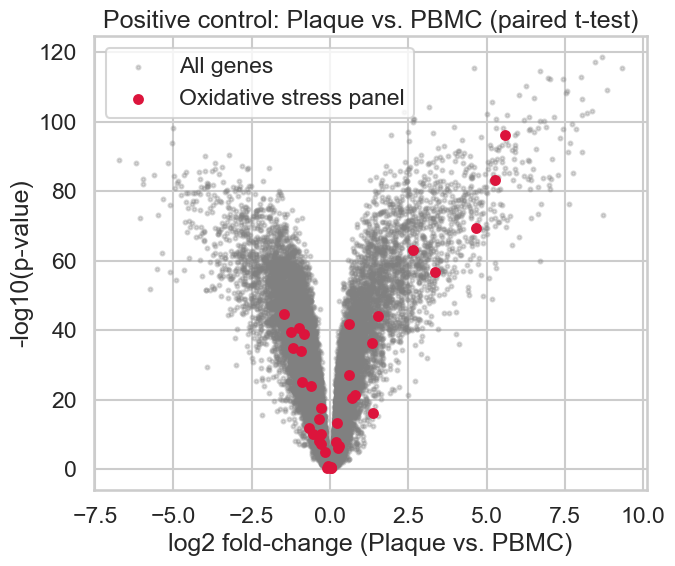

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))
plt.scatter(tissue_de["log2FC_plaque_vs_pbmc"], -np.log10(tissue_de["p_value"]),
            s=8, alpha=0.3, color="grey", label="All genes")
panel_hits = tissue_de[tissue_de["in_panel"]]
plt.scatter(panel_hits["log2FC_plaque_vs_pbmc"], -np.log10(panel_hits["p_value"]),
            s=40, color="crimson", label="Oxidative stress panel")
plt.xlabel("log2 fold-change (Plaque vs. PBMC)")
plt.ylabel("-log10(p-value)")
plt.title("Positive control: Plaque vs. PBMC (paired t-test)")
plt.legend()
plt.tight_layout()
plt.savefig("figures/positive_control_volcano.png", dpi=150)
plt.show()

In [20]:
tissue_de.to_csv("results/differential_expression_plaque_vs_pbmc_positive_control.csv", index=False)
pd.Series(tissue_enrichment).to_csv("results/positive_control_panel_enrichment.csv")
print("Saved.")

Saved.


## Interpretation

**Primary comparison (Symptomatic vs. Asymptomatic plaque, age-adjusted, n=126).** No individual gene reached significance (0/23,520; FDR<0.05, |log2FC|>=0.585), and the oxidative stress panel showed no enrichment by either the threshold-based Fisher's exact test or the more sensitive rank-based (Mann-Whitney) test (panel median |signed score| = 0.231 vs. background 0.339, p=0.96). Both methods agree, arguing against this being an artifact of a single statistical choice.

**Positive control (Plaque vs. PBMC, paired, n=100 matched patients).** Genome-wide, 9,476/23,520 genes (40.3%) were significant — expected given these are categorically different tissue types (vascular wall vs. circulating blood cells). The oxidative stress panel was significantly enriched above this already-high background by the Fisher's exact test (21/37 panel genes significant vs. 40.3% background rate; OR=1.95, p=0.031), consistent with the established biology of macrophage/foam-cell-driven ROS production in plaque relative to PBMC. The rank-based test did not confirm this (p=0.37), most likely because the very high statistical power of this paired, large-effect comparison compresses nearly the whole transcriptome toward extreme significance, leaving the rank test with little room to discriminate — the threshold-based test, which additionally requires a real fold-change, remains informative in this regime.

**Overall.** The positive control demonstrates that this pipeline and gene panel are capable of detecting real, biologically expected signal when it is present. Read against that, the null result in the primary comparison is best interpreted as evidence that any oxidative-stress transcriptional difference between symptomatic and asymptomatic plaque, if real, is smaller than this single cohort (n=126) can resolve — motivating the multi-cohort, higher-powered approach described in Project Context & Future Directions, rather than indicating a failure of the analytical approach itself.